# Part 2: Can we predict whether an English learner reaches near-native grammar proficiency using only their language background?

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Proprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.dummy import DummyClassifier

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.base import clone

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42

## 1. Load Data from Parquet File

In [25]:
df = pd.read_parquet("clean_learners.parquet")

print(f"Dataset shape: {df.shape}")
print(df.head())
print(df["proficient"].value_counts(normalize=True))

Dataset shape: (355498, 20)
       id  age  gender  Eng_start  years_exposure start_age_group  \
0    11.0   25  female          8              17            8-12   
1    15.0   20  female          6              14             4-7   
2    16.0   37    male         18              19             18+   
3    19.0   29  female         12              17            8-12   
4  1764.0   29  female          4              25             4-7   

   Eng_country_yrs  lived_eng_share  house_Eng  background_missing  \
0             17.0         1.000000        0.0                   0   
1              0.0         0.000000        1.0                   0   
2              0.0         0.000000        0.0                   0   
3              1.0         0.058824        0.0                   0   
4             29.0         1.000000        1.0                   0   

   education_level  psychiatric  prime_Eng  lives_eng_country  n_native_langs  \
0                5            0          1             

## 2. Define Predictor Variables and Outcome Variable
Numeric features and categorical features are separated in preparation for scaling and one-hot encoding

In [26]:
numeric_features = [
    "age", "Eng_start", "years_exposure", "Eng_country_yrs", 
    "lived_eng_share", "house_Eng", "background_missing", 
    "education_level", "psychiatric", "prime_Eng", "lives_eng_country", 
    "n_native_langs", "n_prime_langs"
]

categorical_features = [
    "gender", "start_age_group", "native_lang_grp", "lang_family"
]

X = df[numeric_features + categorical_features]
y = df["proficient"]

## 3. Split Data into Training and Test Data
We will split the dataset into 80% training data and 20% testing data. For hyperparameter tuning, we will use a stratified sample of 50,000 data points due to the size of the dataset.

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=50000,
    random_state=RANDOM_STATE,
    stratify=y_train
)

print(f"Original training set: {X_train.shape}")
print(f"Tuning sample: {X_tune.shape}")

Original training set: (284398, 17)
Tuning sample: (50000, 17)


## 4. Preprocessing Pipeline
Numerical values have to be scaled. Categorical values have to be converted to numbers via one-hot encoding. We will use ColumnTransformer to build this preprocessor.

To analyze this question, we will be using logistic regression, kNN, and decision tree to predict a participant's English proficiency. Additionally, ensembles, such as random forest and gradient boosting, will also be used. 

A pipeline will be built foreach model using the preprocessor to ensure that each model uses the same scaling and encoding process.

In [28]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    )
}

pipelines = {
    name: Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    for name, model in models.items()
}

print("Pipelines created:")
for name in pipelines:
    print(f"- {name}")

Pipelines created:
- Logistic Regression
- KNN
- Decision Tree
- Random Forest
- Gradient Boosting


## 5. Hyperparameter Tuning
First, we define lists of hyperparamter values to test for each model.
We will be using GridSearchCV to streamline this process since many models have multiple hyperparameters.

Due to our large training data, we will tune the hyperparameters on a stratified sample set, using a 5-fold validation loop, storing the best estimators along with its parameters and F1 scores. Then, those models will be trained on the full training set.

In [29]:
# Hyperparameters to test.
param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10]
    },

    "KNN": {
        "model__n_neighbors": [4, 8, 16, 32],
        "model__weights": ["uniform", "distance"],
    },

    "Decision Tree": {
        "model__max_depth": [5, 10, 20, None],
        "model__min_samples_split": [2, 10, 20],
        "model__min_samples_leaf": [1, 5, 10]
    },

    "Random Forest": {
        "model__n_estimators": [50, 100, 200],
        "model__max_depth": [10, 20, None],
        "model__min_samples_leaf": [1, 5],
    },

    "Gradient Boosting": {
        "model__n_estimators": [50, 100, 200],
        "model__learning_rate": [0.01, 0.1, 0.2],
        "model__max_depth": [2, 3, 5],
        "model__subsample": [0.8, 1.0]
    }
}

In [30]:
# Cross validation loop with stratified sample.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best_models = {}
tuning_results = []

for name, pipeline in pipelines.items():

    print(f"\nTuning {name}")

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring={
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        refit="f1",
        cv=cv,
        n_jobs=-1,
        verbose=1
    )
    search.fit(X_tune, y_tune)

    best_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best F1": search.best_score_,
        "Best Parameters": search.best_params_
    })

    print(f"Best F1: {search.best_score_: .4f}")
    print(f"Best parameters: {search.best_params_}")


Tuning Logistic Regression
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best F1:  0.6046
Best parameters: {'model__C': 0.1}

Tuning KNN
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best F1:  0.4978
Best parameters: {'model__n_neighbors': 32, 'model__weights': 'distance'}

Tuning Decision Tree
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best F1:  0.5925
Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__min_samples_split': 20}

Tuning Random Forest
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best F1:  0.6094
Best parameters: {'model__max_depth': 20, 'model__min_samples_leaf': 5, 'model__n_estimators': 100}

Tuning Gradient Boosting
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best F1:  0.5292
Best parameters: {'model__learning_rate': 0.2, 'model__max_depth': 5, 'model__n_estimators': 100, 'model__subsample': 0.8}


In [31]:
# Display the best parameters.
tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    by="Best F1",
    ascending=False
)

display(tuning_df)

,Model,Best F1,Best Parameters
3,Random Forest,0.609437,"{'model__max_depth': 20, 'model__min_samples_l..."
0,Logistic Regression,0.604590,{'model__C': 0.1}
2,Decision Tree,0.592525,"{'model__max_depth': 10, 'model__min_samples_l..."
4,Gradient Boosting,0.529176,"{'model__learning_rate': 0.2, 'model__max_dept..."
1,KNN,0.497782,"{'model__n_neighbors': 32, 'model__weights': '..."


In [32]:
# Retrain on full training set.
final_models = {}

baseline = DummyClassifier(strategy="constant", constant=1).fit(X_train, y_train)
final_models["Baseline"] = baseline

for name, best_model in best_models.items():
    final_model = clone(best_model)
    final_model.fit(X_train, y_train)
    final_models[name] = final_model

## 6. Model Evaluation
We will compare the models' performance using F1, ROC-AUC, precision, and recall. Then, a confusion matrix will be made for each model.

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
4,Random Forest,0.6712,0.5372,0.7288,0.6185,0.7453
3,Decision Tree,0.6584,0.5238,0.7282,0.6093,0.7310
1,Logistic Regression,0.6596,0.5254,0.7185,0.6069,0.7305
5,Gradient Boosting,0.6969,0.6075,0.4844,0.5391,0.7487
0,Baseline,0.3658,0.3658,1.0000,0.5356,0.5000
2,KNN,0.6723,0.5628,0.4656,0.5096,0.6837


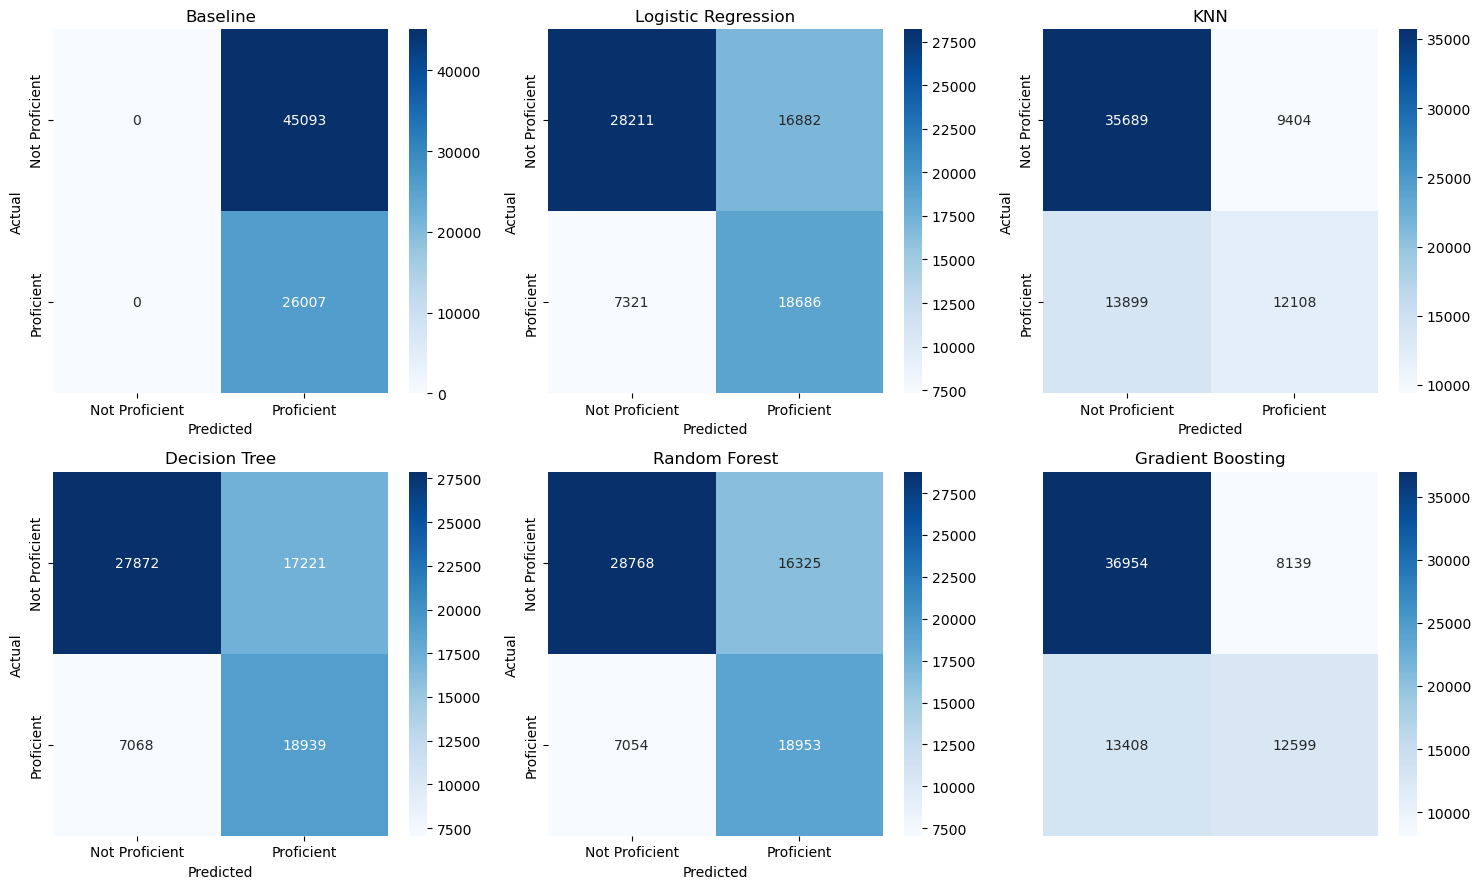

In [33]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
evaluation_results = []

for i, (name, model) in enumerate(final_models.items()):
    # Predict class labels
    y_pred = model.predict(X_test)
    # Predict probability of being proficient
    y_prob = model.predict_proba(X_test)[:, 1]

    # Scores
    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[i],
        xticklabels=["Not Proficient", "Proficient"],
        yticklabels=["Not Proficient", "Proficient"]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

results_df = pd.DataFrame(evaluation_results)
results_df = results_df.sort_values(
    by="F1",
    ascending=False
)
display(results_df.round(4))

axes[-1].axis("off")
plt.tight_layout()
plt.show()

## 7. Feature Importance
Since our random forest model performed the best in terms of F1 scores and ROC/AUC, we will further analyze this model for patterns and insights, starting with feature importance.

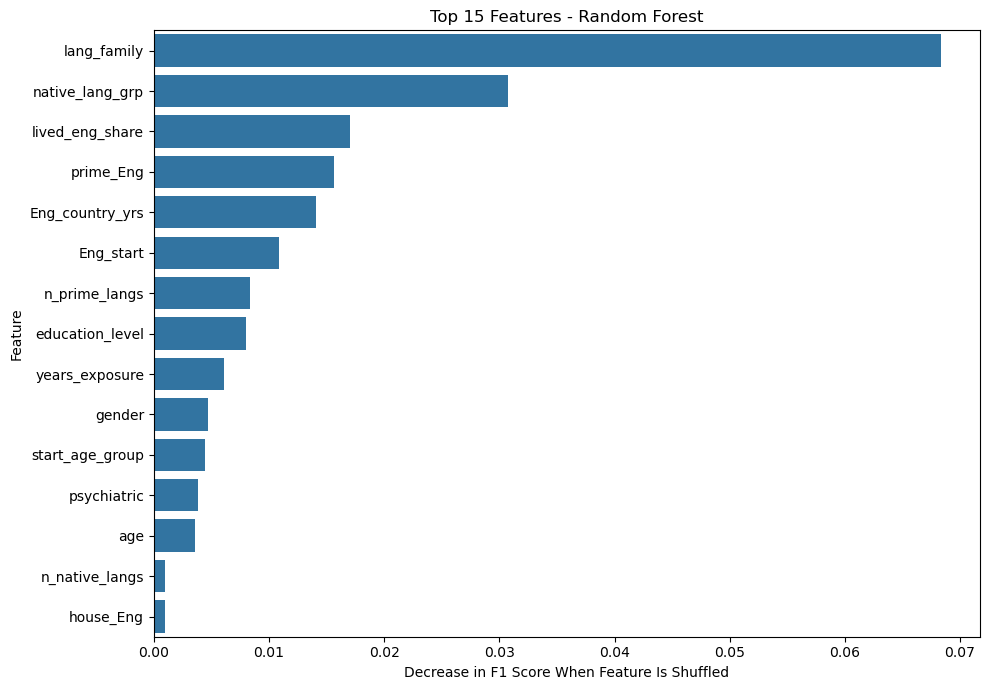

In [34]:
from sklearn.inspection import permutation_importance

rf_model = final_models["Random Forest"]

rf_importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": rf_importance.importances_mean
})

top_features = importance_df.sort_values(by="Importance",ascending=False).head(15)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Features - Random Forest")
plt.xlabel("Decrease in F1 Score When Feature Is Shuffled")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 8. Misclassification Analysis
Next, we will look at how the model misclassifies learners. Since `lang_family` is the most important feature, we can also examine whether these learners share particular language backgrounds. 

In [35]:
rf_model = final_models["Random Forest"]
y_pred = rf_model.predict(X_test)

error_analysis = X_test.copy()

error_analysis["actual"] = y_test
error_analysis["predicted"] = y_pred

# Include participant ID for identification
error_analysis["id"] = df.loc[X_test.index, "id"]

# Identify prediction errors
error_analysis["error_type"] = "Correct"
error_analysis.loc[(error_analysis["actual"] == 0) & (error_analysis["predicted"] == 1), "error_type"] = "False Positive"
error_analysis.loc[(error_analysis["actual"] == 1) & (error_analysis["predicted"] == 0), "error_type"] = "False Negative"

print(error_analysis["error_type"].value_counts())

error_type
Correct           47721
False Positive    16325
False Negative     7054
Name: count, dtype: int64


error_type,Correct,False Negative,False Positive
age,28.984,28.608,30.197
Eng_start,9.735,9.742,8.360
years_exposure,19.249,18.867,21.837
Eng_country_yrs,2.720,0.795,3.749
lived_eng_share,0.117,0.047,0.156
house_Eng,0.137,0.067,0.182
background_missing,0.036,0.038,0.021
education_level,4.472,4.467,4.401
psychiatric,0.035,0.028,0.015
prime_Eng,0.336,0.227,0.460


error_type,Correct,False Negative,False Positive
native_lang_grp,,,
Chinese/Cantonese/Yue,0.684,0.111,0.205
Chinese/Mandarin,0.775,0.099,0.126
Dutch,0.580,0.011,0.410
Finnish,0.535,0.045,0.419
French,0.650,0.148,0.203
German,0.575,0.051,0.374
Hungarian,0.752,0.186,0.063
Italian,0.681,0.170,0.149
Norwegian,0.536,0.023,0.442


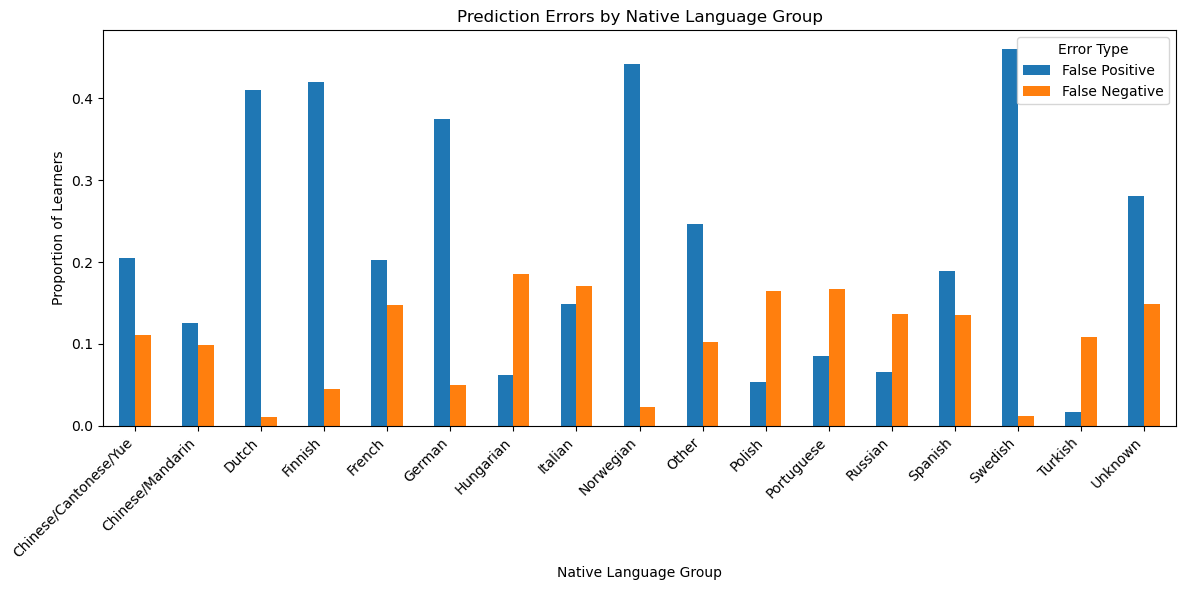

In [36]:
# Compare language background characteristics
numeric_comparison = error_analysis.groupby(
    "error_type"
)[numeric_features].mean().T
display(numeric_comparison.round(3))

# Compare native language background specifically
language_errors = pd.crosstab(
    error_analysis["native_lang_grp"],
    error_analysis["error_type"],
    normalize="index"
)
display(language_errors.round(3))

language_errors[["False Positive", "False Negative"]].plot(
    kind="bar",
    figsize=(12, 6)
)
plt.title("Prediction Errors by Native Language Group")
plt.xlabel("Native Language Group")
plt.ylabel("Proportion of Learners")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Error Type")
plt.tight_layout()
plt.show()

In [37]:
# Actual vs. predicted proficiency rate within each language group
lang_rates = error_analysis.groupby("native_lang_grp").agg(
    n=("actual", "size"),
    actual_proficient=("actual", "mean"),
    predicted_proficient=("predicted", "mean"),
)
# Recall: share of truly proficient learners in each group that the model catches
lang_rates["recall"] = error_analysis[error_analysis["actual"] == 1].groupby("native_lang_grp")["predicted"].mean()

display(lang_rates.sort_values("actual_proficient").round(3))

,n,actual_proficient,predicted_proficient,recall
native_lang_grp,,,,
Turkish,7047,0.126,0.034,0.137
Russian,5183,0.226,0.155,0.393
Polish,3766,0.235,0.123,0.298
Hungarian,4532,0.242,0.119,0.232
Portuguese,2014,0.256,0.173,0.346
Chinese/Mandarin,2034,0.341,0.368,0.710
Spanish,3241,0.345,0.398,0.607
Italian,1784,0.358,0.336,0.524
French,2349,0.395,0.450,0.626


The random forest model correctly classified 47,628 correct, while producing 16,598 false positives and 6,874 false negatives. This indicates that the model was more likely to overestimate proficiency than underestimate it. This is expected with class_weight="balanced", which makes the model more willing to predict the smaller "proficient" class.

Comparisons of learner characteristics revealed differences between correctly and incorrectly classified individuals. False-negative learners generally had less English exposure, fewer years living in an English-speaking country, and lower levels of English use at home. In contrast, false-positive learners tended to have greater English exposure and more frequent English use at home. This suggests that although language background characteristics provide useful predictive information, they do not fully explain individual differences in grammar proficiency.

Prediction errors also varied across native-language groups. For example, Swedish, Norwegian, Finnish, and Dutch learners had relatively high proportions of false-positive predictions in the test set. These patterns suggest that the relationship between language background and grammar proficiency may differ across language groups. The table above accounts for group sizes and actual class distributions by comparing each group's actual proficiency rate with the rate the model predicts. For example, the model predicts about 97% of Dutch learners as proficient when only about 57% actually are, while it catches only about 14% of proficient Turkish learners (recall). This suggests the model relies heavily on native-language group averages rather than individual background, which would be unfair to proficient learners from lower-scoring language groups.